# Fine-tuning de Phi-3 sur les poèmes rimés, dans Google Colab

Ce notebook reprend les réglages du pipeline de la branche `Clémence`, mais tout tourne dans Colab, sur une carte graphique T4.

Il suit les mêmes étapes que le pipeline :
1. Préparer les données (séance 2).
2. Tester Phi-3 avant l'entraînement, pour avoir un point de comparaison.
3. Fine-tuner Phi-3 avec LoRA (séance 3).
4. Générer les réponses aux questions de test et calculer la note de rimes (séance 3).

Avec seulement 10 exemples, c'est un test technique : il vérifie que tout fonctionne, mais le modèle ne peut pas encore bien apprendre.

**Avant de commencer :** menu `Exécution > Modifier le type d'exécution`, puis choisir **GPU T4**.

## 1. Installer les bibliothèques

Ce sont les mêmes versions que dans le pipeline : le cours impose `transformers` 4.46 et `peft` 0.13.2 pour rester compatible avec le déploiement sur Vertex AI.

Colab a déjà d'autres versions installées. **Après cette cellule, redémarre la session** (`Exécution > Redémarrer la session`), puis continue à la cellule suivante sans relancer celle-ci.

In [1]:
!pip install -q "transformers==4.46.3" "peft==0.13.2" "trl==0.12.2" "accelerate==1.1.1" "datasets==3.6.0" "bitsandbytes==0.48.0" "pronouncing==0.2.0"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Vérifier la carte graphique

Le fine-tuning a besoin d'une carte graphique NVIDIA. La cellule doit afficher `True` et le nom de la carte, par exemple `Tesla T4`.

In [2]:
import torch
import transformers
import peft
import trl

print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("transformers", transformers.__version__, "| peft", peft.__version__, "| trl", trl.__version__)

GPU available: True
GPU name: Tesla T4
transformers 4.46.3 | peft 0.13.2 | trl 0.12.2


## 3. Charger ton CSV

Une fenêtre s'ouvre : choisis `rhyming_qa_test_v2.csv` sur ton ordinateur. Le fichier doit avoir les colonnes `question` et `poem`.

In [3]:
import pandas as pd
from google.colab import files

uploaded = files.upload()
csv_name = next(iter(uploaded))
df = pd.read_csv(csv_name)

print(csv_name, df.shape)
df.head()

Saving rhyming_qa_100.csv to rhyming_qa_100.csv
rhyming_qa_100.csv (100, 2)


,question,poem
0,Why is the sky blue?,"Sunlight holds every color, it is true,\nBut a..."
1,What is the capital of France?,"Ask about France and its capital's name,\nAnd ..."
2,How do plants make their food?,"Green leaves catch the sunlight every day,\nAn..."
3,Why do we have seasons?,"Earth's axis leans as it circles the sun,\nSo ..."
4,How can I sleep better at night?,"Go to bed at the same time each night,\nAnd pu..."


## 4. Préparer les données (séance 2)

Même code que `data_transformation_component.py` : chaque ligne devient une conversation `user` / `assistant`, puis 20 % des paires sont mises de côté pour le test. Avec la même graine (`seed=42`), on retrouve la même répartition que dans ton test local.

In [4]:
from datasets import Dataset

HYPERPARAMS = {
    "model_id": "microsoft/Phi-3-mini-4k-instruct",
    "test_size": 0.2,
    "validation_size": 0.1,
    "seed": 42,
    "lora_r": 8,
    "lora_alpha": 16,
    "lora_dropout": 0.05,
    "num_train_epochs": 10,
    "learning_rate": 3e-4,
    "per_device_train_batch_size": 16,
    "max_seq_length": 128,
    "max_new_tokens": 96,
}

def to_messages(example):
    return {
        "messages": [
            {"role": "user", "content": example["question"]},
            {"role": "assistant", "content": example["poem"]},
        ]
    }

dataset = Dataset.from_pandas(df).map(to_messages, remove_columns=list(df.columns))
data_splits = dataset.train_test_split(test_size=HYPERPARAMS["test_size"], seed=HYPERPARAMS["seed"])
train_data, test_data = data_splits["train"], data_splits["test"]

# Same as fine_tuning_component.py: part of the training data is kept for validation
fit_splits = train_data.train_test_split(test_size=HYPERPARAMS["validation_size"], seed=HYPERPARAMS["seed"])
fit_data, validation_data = fit_splits["train"], fit_splits["test"]

print(f"Training: {len(fit_data)} | validation: {len(validation_data)} | test: {len(test_data)}")
print("Test questions:", [m[0]["content"] for m in test_data["messages"]])

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Training: 72 | validation: 8 | test: 20
Test questions: ['How does recycling help the planet?', 'Who painted the Mona Lisa?', 'What is a leap year?', 'How does the heart work?', 'What is DNA?', 'What is the capital of Japan?', 'How does the Sun produce energy?', 'How can I reduce stress?', 'What is a hurricane?', 'How does a computer store information?', 'How do plants make their food?', 'What is a black hole?', 'How does the internet work?', 'What is democracy?', 'How can I learn a new language?', 'What is a mammal?', 'What is a volcano?', 'Why do dogs wag their tails?', 'How can I sleep better at night?', 'Why do we pay taxes?']


## 5. Charger Phi-3 et son tokenizer

Le modèle est chargé en 4 bits (quantification, séance 3) pour tenir sur la T4. Le téléchargement prend quelques minutes la première fois.

In [5]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

tokenizer = AutoTokenizer.from_pretrained(HYPERPARAMS["model_id"])
tokenizer.pad_token = tokenizer.unk_token
tokenizer.pad_token_id = tokenizer.unk_token_id
tokenizer.padding_side = "right"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float32,
)
model = AutoModelForCausalLM.from_pretrained(
    HYPERPARAMS["model_id"], device_map={"": 0}, quantization_config=bnb_config
)
print(f"Memory footprint: {model.get_memory_footprint() / 1e6:.0f} MB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

... (4 outputs left out)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

Memory footprint: 2206 MB


## 6. Les fonctions de génération et de notation

`build_prompt`, `generate_response` et `extract_response` viennent de `inference_component.py`. `rhyme_score` vient de `evaluation_component.py` : 1 si les deux paires de vers riment en AABB, 0,5 si une seule rime, 0 sinon ou si le poème n'a pas 4 vers.

In [6]:
import re

import pronouncing

def build_prompt(tokenizer, question):
    messages = [{"role": "user", "content": question}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

def generate_response(model, tokenizer, prompt, **kwargs):
    inputs = tokenizer(prompt, add_special_tokens=False, return_tensors="pt").to(model.device)
    model.eval()
    with torch.no_grad():
        output_ids = model.generate(**inputs, eos_token_id=tokenizer.eos_token_id, **kwargs)
    return tokenizer.batch_decode(output_ids, skip_special_tokens=False)[0]

def extract_response(model_output):
    match = re.search(r"<\|assistant\|>(.*?)(?:<\|end\|>|<\|endoftext\|>|$)", model_output, re.DOTALL)
    return match.group(1).strip() if match else model_output.strip()

def last_word(line):
    words = re.findall(r"[a-z']+", line.lower())
    return words[-1] if words else ""

def words_rhyme(first, second):
    if not first or not second or first == second:
        return False
    first_parts = {pronouncing.rhyming_part(p) for p in pronouncing.phones_for_word(first)}
    second_parts = {pronouncing.rhyming_part(p) for p in pronouncing.phones_for_word(second)}
    return bool(first_parts & second_parts)

def rhyme_score(poem):
    lines = [line.strip() for line in str(poem).splitlines() if line.strip()]
    if len(lines) != 4:
        return 0.0
    words = [last_word(line) for line in lines]
    return (words_rhyme(words[0], words[1]) + words_rhyme(words[2], words[3])) / 2

def answer_test_questions(model):
    rows = []
    for messages in test_data["messages"]:
        question, reference = messages[0]["content"], messages[1]["content"]
        raw_output = generate_response(
            model, tokenizer, build_prompt(tokenizer, question),
            max_new_tokens=HYPERPARAMS["max_new_tokens"], do_sample=False,
        )
        answer = extract_response(raw_output)
        rows.append({"question": question, "answer": answer, "rhyme_score": rhyme_score(answer), "reference": reference})
    return pd.DataFrame(rows)

# Sanity check: your own poems should score 1 (or 0.5 for war / evermore)
print([rhyme_score(m[1]["content"]) for m in test_data["messages"]])

/usr/local/lib/python3.13/dist-packages/pronouncing/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream


[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


## 7. Tester Phi-3 avant l'entraînement

C'est le point de comparaison : sans lui, on ne peut pas montrer ce que le fine-tuning a apporté.

In [7]:
before_df = answer_test_questions(model)
for row in before_df.itertuples():
    print(f"Q: {row.question}\nRhyme score: {row.rhyme_score}\n{row.answer}\n")

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Q: How does recycling help the planet?
Rhyme score: 0.0
Recycling helps the planet in several ways:

1. Reduces waste in landfills: Recycling reduces the amount of waste that ends up in landfills, which can take up valuable land space and contribute to pollution.

2. Conserves natural resources: Recycling helps conserve natural resources by reducing the need to extract and process raw materials. For example, recycling paper saves trees, recycling alumin

Q: Who painted the Mona Lisa?
Rhyme score: 0.0
The Mona Lisa was painted by Leonardo da Vinci. He was an Italian artist, and his work on the Mona Lisa is considered one of the most famous and influential works in the history of art. The painting is believed to have been completed in the early 16th century, around 1503 to 1506, although some sources suggest the work may have continued until 1517. Leonardo da Vinci'

Q: What is a leap year?
Rhyme score: 0.0
A leap year is a year that has one additional day added to keep the calendar year

## 8. Fine-tuner avec LoRA (séance 3)

Mêmes réglages que `fine_tuning_component.py` dans ta branche : `packing=False`, `max_seq_length=128`, et le meilleur modèle selon l'erreur de validation est conservé à la fin.

Pendant l'entraînement, un tableau affiche `Training Loss` et `Validation Loss` à chaque epoch.

In [8]:
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

lora_config = LoraConfig(
    r=HYPERPARAMS["lora_r"],
    lora_alpha=HYPERPARAMS["lora_alpha"],
    lora_dropout=HYPERPARAMS["lora_dropout"],
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["o_proj", "qkv_proj", "gate_up_proj", "down_proj"],
)

sft_config = SFTConfig(
    output_dir="/content/checkpoints",
    num_train_epochs=HYPERPARAMS["num_train_epochs"],
    learning_rate=HYPERPARAMS["learning_rate"],
    per_device_train_batch_size=HYPERPARAMS["per_device_train_batch_size"],
    max_seq_length=HYPERPARAMS["max_seq_length"],
    packing=False,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    optim="paged_adamw_8bit",
    logging_steps=1,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    report_to=["tensorboard"],
    logging_dir="/content/logs",
    seed=HYPERPARAMS["seed"],
)

trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=fit_data,
    eval_dataset=validation_data,
    processing_class=tokenizer,
    peft_config=lora_config,
)
trainer.model.print_trainable_parameters()
train_result = trainer.train()

Map:   0%|          | 0/72 [00:00<?, ? examples/s]

Map:   0%|          | 0/8 [00:00<?, ? examples/s]

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


trainable params: 12,582,912 || all params: 3,833,662,464 || trainable%: 0.3282


Epoch,Training Loss,Validation Loss
1,1.957200,1.843270
2,1.374800,1.481418
3,1.196400,1.377398
4,0.860900,1.363282
5,0.700900,1.472519
6,0.520100,1.673999
7,0.415300,1.907275
8,0.236100,2.084961
9,0.134800,2.212971
10,0.107300,2.277913


## 9. Lire les courbes d'erreur

L'erreur d'entraînement doit baisser. Si l'erreur de validation remonte alors que celle d'entraînement continue de baisser, le modèle commence à réciter : c'est le surapprentissage vu en séance 3. Avec si peu d'exemples, c'est attendu.

         loss  eval_loss
epoch                   
0.2    2.4506        NaN
0.4    2.2486        NaN
0.6    2.2012        NaN
0.8    1.9863        NaN
1.0    1.9572   1.843270
1.2    1.6055        NaN
1.4    1.6504        NaN
1.6    1.4190        NaN
1.8    1.4448        NaN
2.0    1.3748   1.481418
2.2    1.1770        NaN
2.4    1.2574        NaN
2.6    1.1824        NaN
2.8    1.1948        NaN
3.0    1.1964   1.377398
3.2    1.1046        NaN
3.4    1.0071        NaN
3.6    0.8851        NaN
3.8    0.9348        NaN
4.0    0.8609   1.363282
4.2    0.8191        NaN
4.4    0.7644        NaN
4.6    0.6475        NaN
4.8    0.8037        NaN
5.0    0.7009   1.472519
5.2    0.6236        NaN
5.4    0.5483        NaN
5.6    0.5265        NaN
5.8    0.4778        NaN
6.0    0.5201   1.673999
6.2    0.3257        NaN
6.4    0.3777        NaN
6.6    0.3587        NaN
6.8    0.2958        NaN
7.0    0.4153   1.907275
7.2    0.2422        NaN
7.4    0.2316        NaN
7.6    0.2193        NaN


<Axes: title={'center': 'Training and validation loss'}, xlabel='epoch'>

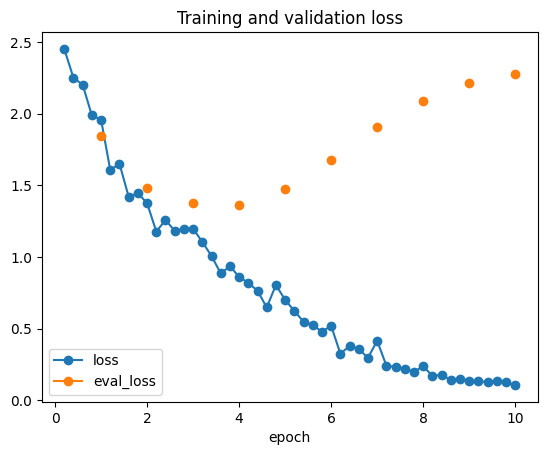

In [9]:
history = pd.DataFrame(trainer.state.log_history)
loss_table = history.groupby("epoch")[["loss", "eval_loss"]].mean()
print(loss_table)
loss_table.plot(marker="o", title="Training and validation loss")

## 10. Tester Phi-3 après l'entraînement

On pose les mêmes questions de test, jamais vues pendant l'entraînement, puis on compare avant et après.

In [10]:
after_df = answer_test_questions(trainer.model)
for before, after in zip(before_df.itertuples(), after_df.itertuples()):
    print(f"Q: {after.question}")
    print(f"--- Before (rhyme score {before.rhyme_score})\n{before.answer}")
    print(f"--- After (rhyme score {after.rhyme_score})\n{after.answer}")
    print(f"--- Reference\n{after.reference}\n")

print("Mean rhyme score before:", before_df["rhyme_score"].mean())
print("Mean rhyme score after:", after_df["rhyme_score"].mean())

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Q: How does recycling help the planet?
--- Before (rhyme score 0.0)
Recycling helps the planet in several ways:

1. Reduces waste in landfills: Recycling reduces the amount of waste that ends up in landfills, which can take up valuable land space and contribute to pollution.

2. Conserves natural resources: Recycling helps conserve natural resources by reducing the need to extract and process raw materials. For example, recycling paper saves trees, recycling alumin
--- After (rhyme score 0.5)
Recycling saves energy and reduces waste,
By reusing materials that we once used;
It cuts down on pollution in the air,
And helps us use resources more with care.
--- Reference
Recycling turns old things into new,
So we use fewer trees and mine less too;
It keeps waste out of landfills and seas,
And saves lots of energy with ease.

Q: Who painted the Mona Lisa?
--- Before (rhyme score 0.0)
The Mona Lisa was painted by Leonardo da Vinci. He was an Italian artist, and his work on the Mona Lisa is co

## 11. Tester avec tes propres questions

Remplace la question pour voir comment le modèle répond à un sujet absent de tes données.

In [11]:
question = "Why do cats purr?"
raw_output = generate_response(
    trainer.model, tokenizer, build_prompt(tokenizer, question),
    max_new_tokens=HYPERPARAMS["max_new_tokens"], do_sample=False,
)
answer = extract_response(raw_output)
print(answer)
print("Rhyme score:", rhyme_score(answer))

Cats purr when they are happy or scared,
It helps them feel calm and keeps them secure;
It can soothe their own pain or a friend's,
And mothers purr to their kittens every night.
Rhyme score: 0.0


## 12. Garder les résultats

Les fichiers de Colab disparaissent à la fin de la session. Cette cellule télécharge les réponses et l'adaptateur LoRA (environ 50 Mo).

In [12]:
import shutil

comparison = after_df.rename(columns={"answer": "answer_after", "rhyme_score": "rhyme_after"})
comparison.insert(1, "answer_before", before_df["answer"])
comparison.insert(2, "rhyme_before", before_df["rhyme_score"])
comparison.to_csv("colab_predictions.csv", index=False)

trainer.save_model("/content/phi3-rhyming-adapter")
tokenizer.save_pretrained("/content/phi3-rhyming-adapter")
shutil.make_archive("/content/phi3-rhyming-adapter", "zip", "/content/phi3-rhyming-adapter")

files.download("colab_predictions.csv")
files.download("/content/phi3-rhyming-adapter.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>